In [2]:
import seaborn as sns
from sklearn.datasets import make_blobs

In [3]:
# cluster

X, y = make_blobs (
    n_samples = 1000,
    n_features = 20,
    centers = 4,
    random_state = 42
)

<Axes: >

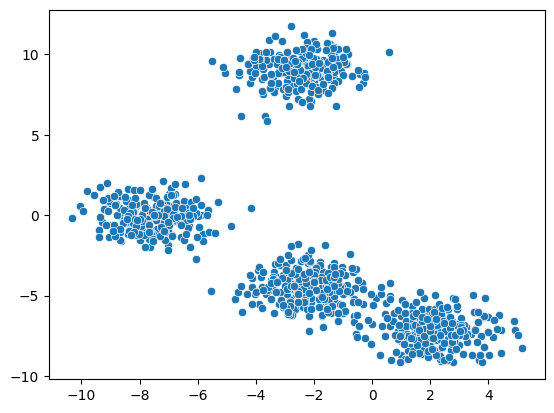

In [4]:
# visualize -

sns.scatterplot(x = X[:, 0], y = X[:, 1])

In [6]:
# scale neccessary -
#  K means
from sklearn.cluster import KMeans

In [7]:

K = 4

kmeans = KMeans(
    n_clusters = K,
    random_state = 42
)

In [8]:
labels = kmeans.fit_predict(X)
labels # clusters

array([0, 3, 1, 3, 3, 2, 3, 0, 1, 2, 1, 3, 3, 0, 3, 0, 0, 1, 1, 2, 1, 0,
       2, 1, 1, 1, 2, 3, 1, 3, 0, 2, 2, 1, 2, 0, 0, 0, 0, 0, 1, 1, 3, 2,
       1, 3, 2, 0, 0, 0, 0, 1, 1, 3, 0, 2, 1, 2, 0, 1, 3, 0, 0, 3, 3, 3,
       2, 0, 3, 2, 0, 3, 1, 2, 2, 2, 3, 0, 2, 1, 3, 0, 3, 3, 0, 0, 0, 0,
       2, 2, 0, 1, 2, 1, 2, 1, 0, 0, 2, 1, 1, 3, 2, 3, 1, 0, 3, 0, 1, 2,
       3, 3, 3, 0, 2, 0, 3, 0, 0, 1, 3, 1, 0, 3, 2, 2, 3, 2, 2, 2, 1, 1,
       0, 3, 1, 1, 3, 3, 3, 3, 1, 2, 1, 1, 3, 3, 3, 2, 2, 3, 3, 2, 0, 1,
       1, 3, 1, 1, 3, 2, 0, 3, 0, 3, 3, 0, 3, 0, 3, 1, 2, 3, 1, 1, 2, 0,
       1, 3, 0, 2, 2, 3, 0, 0, 1, 3, 2, 1, 2, 0, 3, 0, 2, 2, 3, 1, 0, 2,
       2, 0, 1, 3, 0, 1, 1, 3, 1, 1, 3, 1, 1, 3, 3, 1, 1, 1, 1, 2, 3, 2,
       0, 0, 2, 2, 3, 0, 0, 3, 0, 0, 1, 3, 3, 0, 0, 1, 3, 2, 1, 1, 1, 3,
       3, 3, 3, 1, 3, 1, 1, 1, 0, 2, 2, 2, 3, 0, 2, 3, 0, 1, 2, 1, 2, 0,
       3, 0, 0, 0, 2, 2, 1, 1, 2, 0, 0, 1, 1, 1, 3, 3, 0, 2, 1, 3, 0, 2,
       3, 1, 1, 0, 0, 0, 2, 1, 3, 0, 2, 3, 1, 1, 1,

<Axes: >

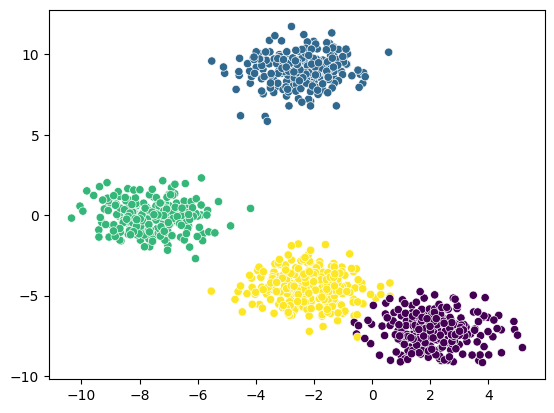

In [9]:
# cluster check
sns.scatterplot(x = X[:, 0], y = X[:, 1], c=labels)

# Choosing K

In [11]:
# Elbow method --

wcss = []
for k in range(1, 21):
    kmeans = KMeans(n_clusters = k)
    kmeans.fit_predict(X)
    wcss.append(kmeans.inertia_)


<Axes: >

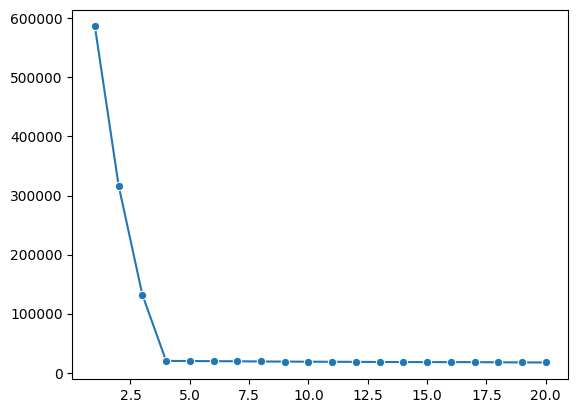

In [12]:

sns.lineplot(x = range(1, 21) , y = wcss , marker='o')

In [ ]:
# elbow point is approx == 4

In [19]:
# kneed module -
!pip install kneed
from kneed import KneeLocator

In [20]:

knee = KneeLocator( range(1,21) , wcss , curve="convex", direction="decreasing")

print(knee.elbow)

4


# Silhoutee score

In [14]:
from sklearn.metrics import silhouette_score

In [17]:
ss = []

for k in range(2, 21):
    kmeans = KMeans(n_clusters = k)
    labels = kmeans.fit_predict(X)
    score = silhouette_score( X , labels)

    ss.append(score)

<Axes: >

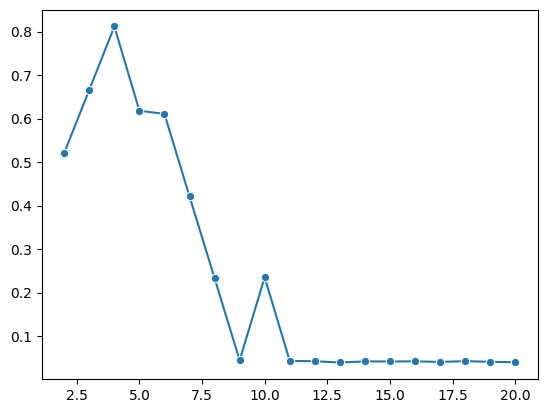

In [18]:
# plot -

sns.lineplot( x=range(2,21) , y=ss, marker='o' )

In [ ]:
# graph is at peak on 4 ! k=4